# Part 7: Combining the GARCH and ML Forecasts

### Ramith Vaid | NTU Singapore

Parts 4 and 6 produced daily 21-day volatility forecasts from GARCH(1,1) and from several machine learning models on the same scored days, with the same target, embargo and blocks. If the two kinds of model make different errors, an average of them can beat both. This part tests that directly, with nothing new to fit: every forecast comes from `part4_forecasts.csv` (ten assets: GARCH, Gradient Boosting on the Part 1 features, naive) and `part6_forecasts.csv` (six assets: GARCH, HAR, Gradient Boosting variants, Ridge, GRU, naive).

**What is tested.**
1. *Error correlation.* The correlation between GARCH's forecast errors and each ML model's errors. An average only helps if the correlation is well below 1 and the two models have similar accuracy.
2. *Equal-weight averages.* GARCH plus the Part 1 Gradient Boosting model on ten assets; on six assets, GARCH plus HAR, Ridge or the GRU, and averages of several of them. Compared with GARCH, with each component and with the better component.
3. *Weights learned from the past.* For blocks 2 and 3 only, the mixing weight between GARCH and one ML model is chosen to minimize squared error over the previous block and applied to the current block (block 1 has no earlier block). This is what could actually be done in practice, set against the 50/50 average and against an oracle weight chosen on the block itself, which shows the most any fixed weight could have achieved and is not tradable.

Evaluation uses RMSE in annualized percentage points and Diebold-Mariano tests with 20 Newey-West lags. All forecasts are for days t+1 to t+21 made at the close of day t; the blocks are the last three 250-day blocks with a complete forward window.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from garch_utils import dm_test, score_forecasts
print('Libraries loaded.')

Libraries loaded.


## 1. Load the earlier forecasts

In [2]:
p4 = pd.read_csv('part4_forecasts.csv', parse_dates=['date']).rename(columns={'ml': 'gbr1'})
p6 = pd.read_csv('part6_forecasts.csv', parse_dates=['date'])
print('Part 4:', p4['ticker'].nunique(), 'assets,', len(p4), 'rows; Part 6:', p6['ticker'].nunique(), 'assets,', len(p6), 'rows')
chk = p4.merge(p6[['date', 'ticker', 'actual', 'garch']], on=['date', 'ticker'], suffixes=('', '_p6'))
print('Part 4 and Part 6 share', len(chk), 'rows; largest difference between their targets:',
      f"{(chk['actual'] - chk['actual_p6']).abs().max():.5f} annualized pp (small revisions to adjusted prices between downloads);",
      'GARCH forecasts identical:', bool(np.allclose(chk['garch'], chk['garch_p6'])))
six = p6.merge(p4[['date', 'ticker', 'gbr1']], on=['date', 'ticker'], how='left')

Part 4: 10 assets, 7500 rows; Part 6: 6 assets, 4500 rows
Part 4 and Part 6 share 4500 rows; largest difference between their targets: 0.00014 annualized pp (small revisions to adjusted prices between downloads); GARCH forecasts identical: True


## 2. Do GARCH and the ML models make different errors?

Correlation of forecast errors (forecast minus actual) between GARCH and each ML model, per asset, pooled over the 750 days. Values near 1 mean the models fail on the same days.

In [3]:
rows = []
for tk, g in p4.groupby('ticker', sort=False):
    rows.append({'ticker': tk, 'model': 'gbr1', 'error_corr_with_garch': np.corrcoef(g['garch'] - g['actual'], g['gbr1'] - g['actual'])[0, 1],
                 'rmse_garch': score_forecasts(g['actual'], g['garch'])['rmse'], 'rmse_model': score_forecasts(g['actual'], g['gbr1'])['rmse']})
for tk, g in six.groupby('ticker', sort=False):
    for m in ('har', 'ridge_rich', 'gru', 'gbr_rich'):
        rows.append({'ticker': tk, 'model': m, 'error_corr_with_garch': np.corrcoef(g['garch'] - g['actual'], g[m] - g['actual'])[0, 1],
                     'rmse_garch': score_forecasts(g['actual'], g['garch'])['rmse'], 'rmse_model': score_forecasts(g['actual'], g[m])['rmse']})
ec = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 200)
print(ec.pivot(index='ticker', columns='model', values='error_corr_with_garch').to_string())
print()
print('Mean error correlation with GARCH:', ec.groupby('model')['error_corr_with_garch'].mean().round(3).to_dict())

model     gbr1  gbr_rich   gru   har  ridge_rich
ticker                                          
AAPL     0.865     0.822 0.881 0.962       0.937
BTC-USD  0.906       NaN   NaN   NaN         NaN
EEM      0.880     0.791 0.921 0.970       0.913
EURUSD=X 0.903       NaN   NaN   NaN         NaN
GLD      0.811     0.737 0.707 0.888       0.886
JPM      0.860     0.783 0.896 0.943       0.877
TLT      0.835       NaN   NaN   NaN         NaN
VNQ      0.774       NaN   NaN   NaN         NaN
XOM      0.812     0.804 0.819 0.934       0.899
^GSPC    0.792     0.798 0.857 0.938       0.877

Mean error correlation with GARCH: {'gbr1': 0.844, 'gbr_rich': 0.789, 'gru': 0.847, 'har': 0.939, 'ridge_rich': 0.898}


## 3. Equal-weight averages

For each asset, the pooled RMSE of GARCH, the ML model(s) and the average, and the ensemble's RMSE as a ratio to GARCH. First GARCH plus the Part 1 Gradient Boosting model on all ten assets, then the six-asset set with the Part 6 models.

In [4]:
def rm(g, col):
    return score_forecasts(g['actual'], g[col])['rmse']

# Ten assets: GARCH + GBR (Part 1)
p4['avg_garch_gbr1'] = 0.5 * p4['garch'] + 0.5 * p4['gbr1']
rows = []
for tk, g in p4.groupby('ticker', sort=False):
    r = {'ticker': tk, 'garch': rm(g, 'garch'), 'gbr1': rm(g, 'gbr1'), 'average': rm(g, 'avg_garch_gbr1')}
    r['avg_over_garch'] = r['average'] / r['garch']
    r['avg_over_best_component'] = r['average'] / min(r['garch'], r['gbr1'])
    la = (g['avg_garch_gbr1'] - g['actual']) ** 2
    r['dm_vs_garch'], r['p_vs_garch'] = dm_test(la, (g['garch'] - g['actual']) ** 2, 20)
    r['dm_vs_gbr1'], r['p_vs_gbr1'] = dm_test(la, (g['gbr1'] - g['actual']) ** 2, 20)
    rows.append(r)
ens10 = pd.DataFrame(rows)
print(ens10.to_string(index=False))
print()
print('Average beats GARCH on', int((ens10['avg_over_garch'] < 1).sum()), 'of 10 assets, beats the Gradient Boosting model on',
      int((ens10['average'] < ens10['gbr1']).sum()), ', beats both on', int(((ens10['average'] < ens10['garch']) & (ens10['average'] < ens10['gbr1'])).sum()),
      '; mean ratio to GARCH', round(ens10['avg_over_garch'].mean(), 3))
print('Diebold-Mariano p < 0.05 against GARCH:', int((ens10['p_vs_garch'] < 0.05).sum()), '; against Gradient Boosting:', int((ens10['p_vs_gbr1'] < 0.05).sum()))

  ticker  garch   gbr1  average  avg_over_garch  avg_over_best_component  dm_vs_garch  p_vs_garch  dm_vs_gbr1  p_vs_gbr1
     JPM  8.363  9.110    8.423           1.007                    1.007        0.261       0.794      -1.786      0.074
   ^GSPC  7.280  8.521    7.482           1.028                    1.028        0.445       0.656      -1.119      0.263
    AAPL 11.371 10.489   10.553           0.928                    1.006       -1.720       0.086       0.262      0.794
     XOM  6.857  7.039    6.613           0.964                    0.964       -1.180       0.238      -1.496      0.135
     EEM  7.237  7.671    7.227           0.999                    0.999       -0.053       0.958      -1.326      0.185
     VNQ  5.660  7.725    6.272           1.108                    1.108        0.692       0.489      -1.014      0.311
     GLD  8.794  8.738    8.287           0.942                    0.948       -1.149       0.251      -2.343      0.019
     TLT  3.473  3.556    3.350 

In [5]:
# Six assets: GARCH + Part 6 models
combos = {
    'garch + har': ['garch', 'har'],
    'garch + ridge': ['garch', 'ridge_rich'],
    'garch + gru': ['garch', 'gru'],
    'garch + ridge + gru': ['garch', 'ridge_rich', 'gru'],
    'garch + har + ridge + gru': ['garch', 'har', 'ridge_rich', 'gru'],
    'har + ridge + gru (no garch)': ['har', 'ridge_rich', 'gru'],
    'garch + gbr (Part 1)': ['garch', 'gbr1'],
}
for name, cols in combos.items():
    six[name] = six[cols].mean(axis=1)
singles = ['garch', 'har', 'ridge_rich', 'gru', 'gbr1']
rows = []
for tk, g in six.groupby('ticker', sort=False):
    row = {'ticker': tk}
    for c in singles + list(combos):
        row[c] = rm(g, c)
    rows.append(row)
ens6 = pd.DataFrame(rows).set_index('ticker')
ratio6 = ens6.div(ens6['garch'], axis=0)
print('RMSE relative to GARCH (below 1 beats GARCH), six assets:')
print(ratio6.to_string())
print()
print('Mean ratio:'); print(ratio6.mean().round(3).to_string())
best_single = ens6[['har', 'ridge_rich', 'gru']].min(axis=1)
print()
print('Ensembles with RMSE below the best of HAR / Ridge / GRU on the asset:')
for c in combos:
    print(f'  {c:<30} {int((ens6[c] < best_single).sum())} of 6 assets')

RMSE relative to GARCH (below 1 beats GARCH), six assets:
        garch   har  ridge_rich   gru  gbr1  garch + har  garch + ridge  garch + gru  garch + ridge + gru  garch + har + ridge + gru  har + ridge + gru (no garch)  garch + gbr (Part 1)
ticker                                                                                                                                                                                  
JPM     1.000 1.044       1.015 0.988 1.089        1.007          0.975        0.966                0.964                      0.974                         0.983                 1.007
^GSPC   1.000 0.900       0.873 0.854 1.171        0.935          0.906        0.894                0.876                      0.876                         0.857                 1.028
AAPL    1.000 0.938       0.913 0.873 0.922        0.959          0.941        0.907                0.905                      0.909                         0.894                 0.928
XOM     1.000 0.9

In [6]:
rows = []
for tk, g in six.groupby('ticker', sort=False):
    for name in ('garch + gru', 'garch + ridge', 'garch + har + ridge + gru'):
        la = (g[name] - g['actual']) ** 2
        for ref in ('garch', 'gru', 'ridge_rich'):
            s, p = dm_test(la, (g[ref] - g['actual']) ** 2, 20)
            rows.append({'ticker': tk, 'ensemble': name, 'versus': ref, 'dm': s, 'p': p})
dm6 = pd.DataFrame(rows)
sig = dm6[(dm6.p < 0.05)]
print('Ensemble-vs-component Diebold-Mariano tests with p < 0.05 (negative = ensemble better):')
print(sig.to_string(index=False) if len(sig) else 'none')
print('out of', len(dm6), 'tests')

Ensemble-vs-component Diebold-Mariano tests with p < 0.05 (negative = ensemble better):
ticker                  ensemble     versus     dm     p
   XOM               garch + gru      garch -2.717 0.007
   XOM             garch + ridge      garch -2.186 0.029
   XOM garch + har + ridge + gru      garch -2.851 0.004
   XOM garch + har + ridge + gru ridge_rich -2.417 0.016
   GLD               garch + gru        gru -2.364 0.018
   GLD             garch + ridge        gru -2.189 0.029
   GLD garch + har + ridge + gru        gru -2.094 0.037
out of 54 tests


## 4. Weights learned from the previous block

For each asset and each of blocks 2 and 3, the weight `w` on GARCH (the rest on the ML model) is the value on a grid of 0 to 1 in steps of 0.05 that minimizes squared error over the previous block, then applied to the current block. Compared, on the same 500 days, with GARCH alone, the ML model alone, the 50/50 average, and an oracle weight chosen on the block being scored (not tradable). Run for the Part 1 Gradient Boosting model on ten assets and for the GRU and Ridge on six.

In [7]:
GRID = np.linspace(0, 1, 21)
def best_w(g_prev, a, b):
    errs = [np.mean((w * g_prev[a] + (1 - w) * g_prev[b] - g_prev['actual']) ** 2) for w in GRID]
    return GRID[int(np.argmin(errs))]

def learned_weights(frame, other):
    rows = []
    for tk, g in frame.groupby('ticker', sort=False):
        for blk, prev in (('block 2', 'block 1'), ('block 3', 'block 2')):
            gp, gc = g[g.block == prev], g[g.block == blk]
            w = best_w(gp, 'garch', other)
            w_or = best_w(gc, 'garch', other)
            mix = lambda ww: ww * gc['garch'] + (1 - ww) * gc[other]
            rows.append({'ticker': tk, 'block': blk, 'other': other, 'w_garch_learned': w, 'w_garch_oracle': w_or,
                         'sq_garch': np.mean((gc['garch'] - gc['actual']) ** 2), 'sq_other': np.mean((gc[other] - gc['actual']) ** 2),
                         'sq_5050': np.mean((mix(0.5) - gc['actual']) ** 2), 'sq_learned': np.mean((mix(w) - gc['actual']) ** 2),
                         'sq_oracle': np.mean((mix(w_or) - gc['actual']) ** 2)})
    return pd.DataFrame(rows)

lw = pd.concat([learned_weights(p4, 'gbr1'), learned_weights(six, 'gru'), learned_weights(six, 'ridge_rich')])
def summarize_lw(df):
    out = []
    for other, g in df.groupby('other'):
        r = {'other': other, 'asset_blocks': len(g)}
        for c in ('garch', 'other', '5050', 'learned', 'oracle'):
            r[f'rmse_{c}'] = np.sqrt(g[f'sq_{c}']).mean()
        r['learned_beats_garch'] = int((g['sq_learned'] < g['sq_garch']).sum())
        r['learned_beats_5050'] = int((g['sq_learned'] < g['sq_5050']).sum())
        r['5050_beats_garch'] = int((g['sq_5050'] < g['sq_garch']).sum())
        r['mean_w_garch_learned'] = g['w_garch_learned'].mean()
        r['mean_w_garch_oracle'] = g['w_garch_oracle'].mean()
        out.append(r)
    return pd.DataFrame(out)
lw_summary = summarize_lw(lw)
print(lw_summary.to_string(index=False))

     other  asset_blocks  rmse_garch  rmse_other  rmse_5050  rmse_learned  rmse_oracle  learned_beats_garch  learned_beats_5050  5050_beats_garch  mean_w_garch_learned  mean_w_garch_oracle
      gbr1            20       7.799       8.426      7.815         8.006        7.532                   10                   7                10                 0.705                0.662
       gru            12       8.833       8.413      8.287         8.591        8.002                    9                   3                10                 0.300                0.367
ridge_rich            12       8.833       8.374      8.371         8.545        8.195                    8                   4                11                 0.388                0.388


## 5. Chart

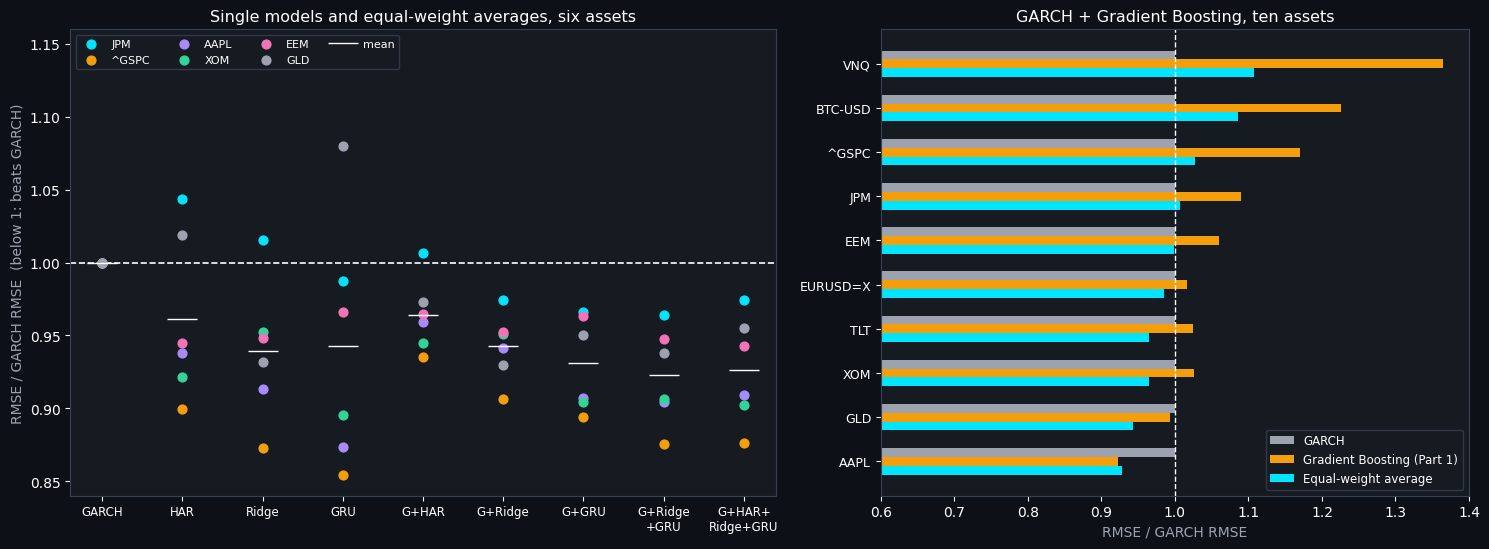

Saved chart_part7_ensemble.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1.2, 1]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
ax = axes[0]
order = ['garch', 'har', 'ridge_rich', 'gru', 'garch + har', 'garch + ridge', 'garch + gru', 'garch + ridge + gru', 'garch + har + ridge + gru']
labels = ['GARCH', 'HAR', 'Ridge', 'GRU', 'G+HAR', 'G+Ridge', 'G+GRU', 'G+Ridge\n+GRU', 'G+HAR+\nRidge+GRU']
x = np.arange(len(order))
for tk, col in zip(ratio6.index, ['#00e5ff', '#f59e0b', '#a78bfa', '#34d399', '#f472b6', '#9ca3af']):
    ax.scatter(x, [ratio6.loc[tk, c] for c in order], color=col, s=40, label=tk, zorder=3)
ax.plot(x, [ratio6[c].mean() for c in order], color='white', marker='_', ms=22, ls='none', label='mean', zorder=4)
ax.axhline(1, color='white', ls='--', lw=1.2)
ax.set_xticks(x)
ax.set_xticklabels(labels, color='white', fontsize=8.5)
ax.set_ylabel('RMSE / GARCH RMSE  (below 1: beats GARCH)', color='#9ca3af')
ax.set_title('Single models and equal-weight averages, six assets', color='white', fontsize=11.5)
ax.set_ylim(0.84, 1.16)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8, ncol=4, loc='upper left')
ax = axes[1]
tk_order = list(ens10.sort_values('avg_over_garch')['ticker'])
y = np.arange(len(tk_order))
e = ens10.set_index('ticker').loc[tk_order]
ax.barh(y + 0.2, e['garch'] / e['garch'], 0.2, color='#9ca3af', label='GARCH')
ax.barh(y, e['gbr1'] / e['garch'], 0.2, color='#f59e0b', label='Gradient Boosting (Part 1)')
ax.barh(y - 0.2, e['average'] / e['garch'], 0.2, color='#00e5ff', label='Equal-weight average')
ax.axvline(1, color='white', lw=1, ls='--')
ax.set_yticks(y)
ax.set_yticklabels(tk_order, color='white', fontsize=9)
ax.set_xlim(0.6, 1.4)
ax.set_xlabel('RMSE / GARCH RMSE', color='#9ca3af')
ax.set_title('GARCH + Gradient Boosting, ten assets', color='white', fontsize=11.5)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8.5, loc='lower right')
plt.tight_layout()
plt.savefig('chart_part7_ensemble.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part7_ensemble.png')

## 6. Summary and saved tables

In [9]:
ec.to_csv('part7_error_correlation.csv', index=False)
ens10.to_csv('part7_ensemble_ten_assets.csv', index=False)
ens6.to_csv('part7_ensemble_six_assets_rmse.csv')
ratio6.to_csv('part7_ensemble_six_assets_ratio.csv')
dm6.to_csv('part7_ensemble_dm_tests.csv', index=False)
lw.to_csv('part7_learned_weights.csv', index=False)
lw_summary.to_csv('part7_learned_weights_summary.csv', index=False)
print('=' * 70)
print('PART 7 SUMMARY: ENSEMBLES')
print('=' * 70)
print('Mean RMSE ratio to GARCH, six assets:')
print(ratio6.mean().round(3).to_string())
print()
print(lw_summary.round(3).to_string(index=False))
print()
print('Files saved: chart_part7_ensemble.png, part7_error_correlation.csv, part7_ensemble_ten_assets.csv, part7_ensemble_six_assets_rmse.csv, part7_ensemble_six_assets_ratio.csv, part7_ensemble_dm_tests.csv, part7_learned_weights.csv, part7_learned_weights_summary.csv')

PART 7 SUMMARY: ENSEMBLES
Mean RMSE ratio to GARCH, six assets:
garch                          1.000
har                            0.961
ridge_rich                     0.939
gru                            0.943
gbr1                           1.044
garch + har                    0.964
garch + ridge                  0.943
garch + gru                    0.931
garch + ridge + gru            0.923
garch + har + ridge + gru      0.927
har + ridge + gru (no garch)   0.925
garch + gbr (Part 1)           0.978

     other  asset_blocks  rmse_garch  rmse_other  rmse_5050  rmse_learned  rmse_oracle  learned_beats_garch  learned_beats_5050  5050_beats_garch  mean_w_garch_learned  mean_w_garch_oracle
      gbr1            20       7.799       8.426      7.815         8.006        7.532                   10                   7                10                 0.705                0.662
       gru            12       8.833       8.413      8.287         8.591        8.002                    9      